<a href="https://colab.research.google.com/github/Tabatha651/METODOS_NUMERICOS/blob/main/MetodoDeNewtonRaphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Método de Newton-Raphson

El método de Newton-Raphson es uno de los métodos numéricos más rápidos para encontrar las raíces de una ecuación de la forma $f(x) = 0$.   

A partir de un valor inicial $p_0$, el método genera una sucesión de aproximaciones mediante la fórmula:

   $$p_n=p_{n-1}-\frac{f(p_{n-1})}{f'(p_{n-1})}\quad\text{para }n\ge1$$


El método utiliza líneas tangentes a la curva. Partiendo de un punto inicial, traza una tangente cuya intersección con el eje $x$ nos da un valor mucho más cercano a la raíz real



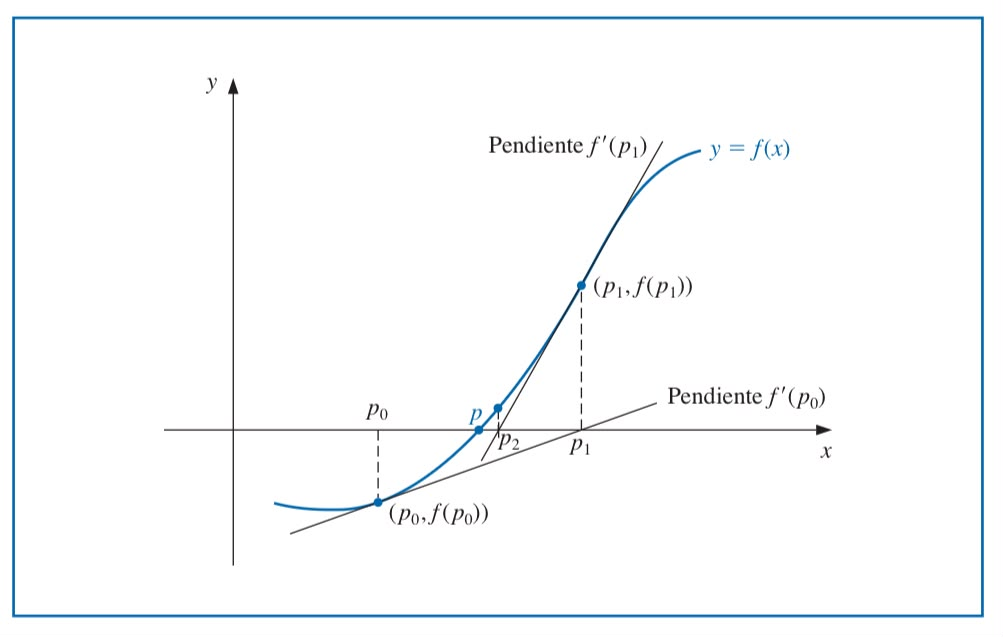

El método asume que el punto inicial $p_0$ está muy cerca de la raíz real. Si $p_0$ se encuentra demasiado lejos, esta suposición matemática deja de ser válida. Como resultado, las líneas tangentes pueden "rebotar" o alejarse de la solución, haciendo que el método diverja o falle

Al contrario si elegimos un punto inicial cerca de la raíz, el método posee una convergencia rápida en comparación con otras técnicas iterativas (Método Bisección / Punto Fijo)

In [121]:
#14/oct/2026 - Prueba
import matplotlib.pyplot as plt #Gráficos (usa alias plt)
import numpy as np #Importa biblioteca Numphy y asigna el alias np

import pandas as pd #Para la tabla que está al final del código


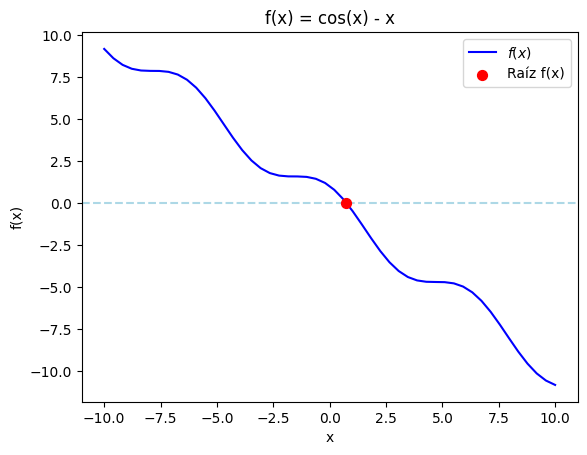

In [132]:
"""----------------------Gráfica f(x)-----------------------------"""
def f(x):
  return np.cos(x)-x   #np está diseñada específicamente para operaciones vectoriales

#Configurar el intervalo para la gráfica
x1=np.linspace(-10,10)
plt.axhline(y=0, linestyle="--", color="lightblue")
#Graficar la función f(x)
plt.plot(x1, f(x1), color="blue", label="$f(x)$")


#Etiquetas y ejes
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("f(x) = cos(x) - x")

#Punto intersección
#punto                                     size   capasup
plt.scatter(0.7390851332151607, 0, color='red', s=50, zorder=5, label='Raíz f(x)')

#Muestra leyenda
plt.legend()
#Muestra gráfico
plt.show()

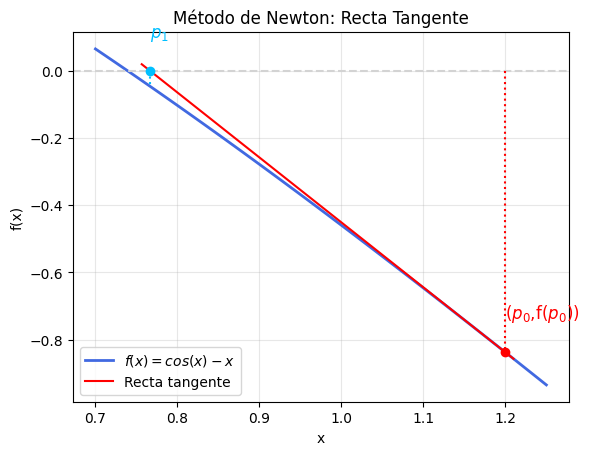

In [128]:
"""-----------Gráfica Método Newton Raphson--------------------"""
#Vamos a trazar dos iteraciones (tangentes en p0 y p1) para mostrar el proceso del método

def f_prima(x): #f'(x)
  return -np.sin(x)-1  #np está diseñada específicamente para operaciones vectoriales

x2=np.linspace(0.7,1.25)
plt.plot(x2, f(x2), color="royalblue", label="$f(x) = cos(x) - x$", linewidth=2)
plt.axhline(y=0, linestyle="--", color="lightgray")

#Definimos aproximación inicial y calculamos la siguiente (p1)
po=1.2
p1=po-f(po)/f_prima(po)   #Usamos fórmula para hallar el punto P1

#Trazamos la recta tangente en p0
x_tan=np.linspace(p1-0.01,po+0.01)      #Definimos un tramo de gráfica, antes de p1 y después de p0
y_tan=f(po)+f_prima(po)*(x_tan-po)
plt.plot(x_tan, y_tan, color="red", linestyle="-", label="Recta tangente")

plt.scatter([po], [f(po)], color="red", zorder=5) #Coloca punto rojo en p0
plt.scatter([p1], [0], color="deepskyblue", zorder=5)     #Punto en p1

plt.text(po, f(po)+0.1, "($p_0$,f($p_0$))", fontsize=12, color="red")
plt.text(p1, 0.1, "$p_1$", fontsize=12, color="deepskyblue")

#Línea punteada vertical para ubicar p0
plt.vlines(po, 0, f(po), color="red", linestyle=":")
plt.vlines(p1, 0, f(p1), color="deepskyblue", linestyle=":")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Método de Newton: Recta Tangente")
plt.legend()
plt.grid(True, alpha=0.3)   #Cuadricula
plt.show()

In [129]:
# -----------------Metodo Newton Raphson----------------------

def metodoNewtonRaphson(p0,tol,nmax_iter):
  i=1
  lError=[]
  lP_1=[]
  lP_n=[]

  while i<=nmax_iter:

    p=p0-(f(p0)/f_prima(p0))    #Siguiente apeoximación
    error=np.abs(p-p0)          #Error absoluto

    lP_1.append(p0)
    lP_n.append(p)
    lError.append(error)


    if error<tol:   #error<tolerancia
      print(f"La raíz encontrada es {p:.8f} en {i} iteraciones")
      return lP_1, lP_n, lError
    i+=1
    p0=p


  print(f"\n\nEl método falló después de {nmax_iter} iteraciones")
  return lP_1, lP_n, lError

In [130]:
"""-----------------------DATOS DE ENTRADA---------------------------------------------"""
#Valores de Entrada
while True:
  try:
    p0=float(input("Ingrese aproximación inicial: "))
    tolerancia=float(input("Ingrese tolerancia: "))
    maximo_iteraciones=int(input("Ingrese número máximo de iteraciones: "))
    if maximo_iteraciones<0:
      print("El número máximo de iteraciones debe ser mayor que cero\n")
      continue
    else: break
  except ValueError:
    print("Los datos ingresados deben de ser de tipo flotante (p0/tolerancia) ó entero (maximo_iteraciones)\n")
    continue


Ingrese aproximación inicial: 1.5
Ingrese tolerancia: 0.00001
Ingrese número máximo de iteraciones: 100


In [131]:

pd.DataFrame(metodoNewtonRaphson(p0,tolerancia,maximo_iteraciones)).T


La raíz encontrada es 0.73908513 en 4 iteraciones


,0,1,2
0,1.500000,0.784472,7.155276e-01
1,0.784472,0.739519,4.495369e-02
2,0.739519,0.739085,4.335351e-04
3,0.739085,0.739085,4.149004e-08
